In [143]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mymlr as mlr

### 1A

Importering af datasæt

In [144]:
df = pd.read_csv('data/cars.csv')
df.describe(percentiles=[]).T

,count,mean,std,min,50%,max
year,9694.0,2.001097e+03,1.107696e+01,1.980000e+03,2.002000e+03,2.018000e+03
product_id,9694.0,4.866750e+02,2.789975e+02,0.000000e+00,5.120000e+02,1.066000e+03
sales,9694.0,5.910339e+04,8.694025e+04,1.000000e+01,2.739400e+04,8.914820e+05
number_households,9694.0,1.072133e+08,1.393279e+07,8.078000e+07,1.093000e+08,1.275900e+08
price,9694.0,3.604769e+01,1.712656e+01,1.114478e+01,3.182023e+01,9.998639e+01
height,9694.0,6.094814e+01,8.411517e+00,4.350000e+01,5.770000e+01,1.075000e+02
footprint,9694.0,1.339263e+04,1.968915e+03,6.514540e+03,1.333006e+04,2.182186e+04
weight,9694.0,3.561211e+03,8.977655e+02,1.113000e+03,3.470500e+03,8.550000e+03
hp,9694.0,1.921820e+02,8.388244e+01,4.400000e+01,1.750000e+02,6.450000e+02
mpg,9694.0,2.093615e+01,6.583005e+00,1.000000e+01,1.900000e+01,5.000000e+01


In [145]:
df['const'] = 1
df['log_number_trims'] = np.log(df['number_trims'])


1A deskriptiv Analyse

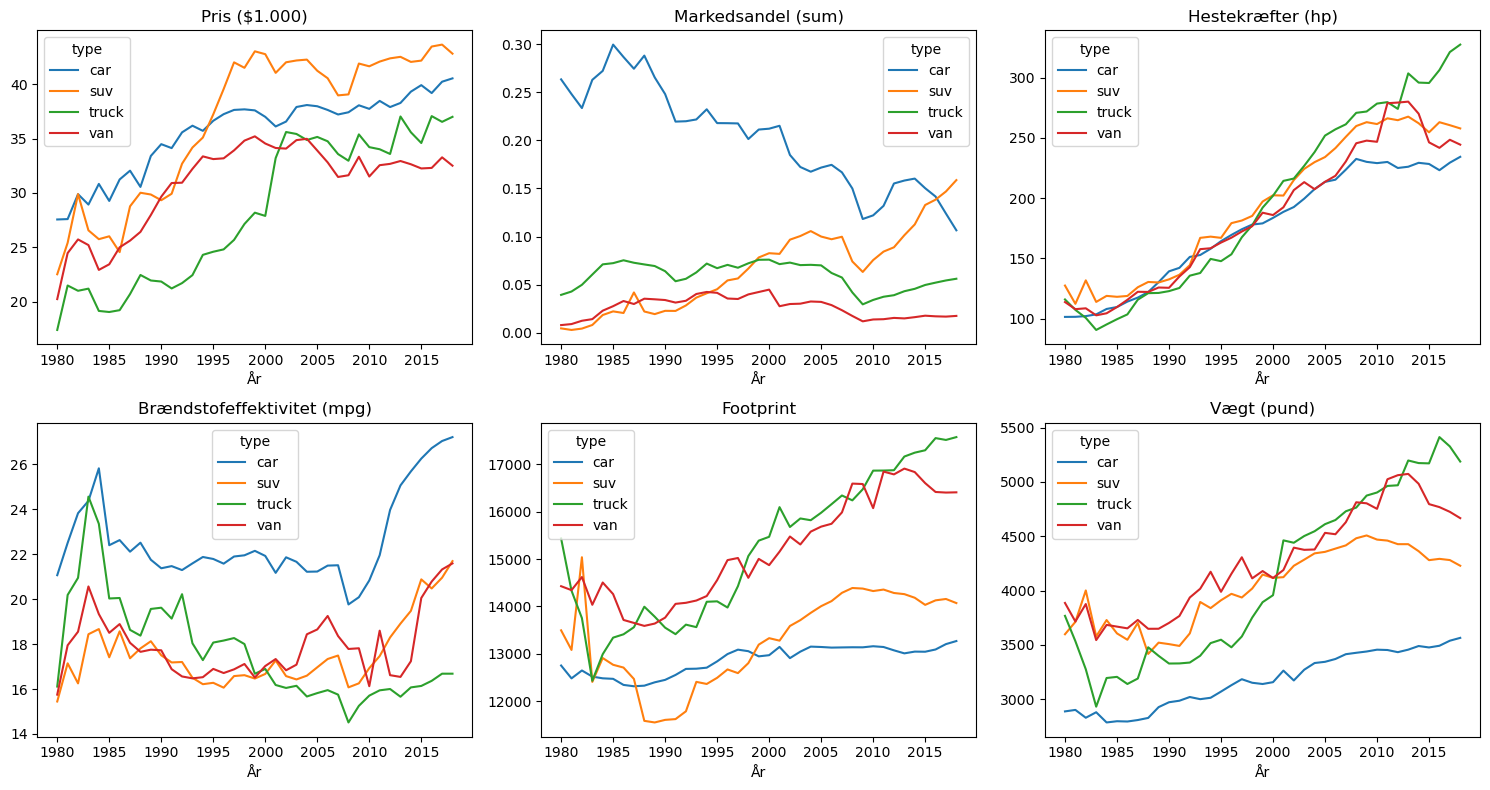

In [146]:
df['type'] = df[['car','suv','truck','van']].idxmax(axis=1)
types = ['car', 'suv', 'truck', 'van']

by = df.groupby(['year','type'])
panels = {
    'Pris ($1.000)': by['price'].mean().unstack(),
    'Markedsandel (sum)': by['market_share'].sum().unstack(),
    'Hestekræfter (hp)': by['hp'].mean().unstack(),
    'Brændstofeffektivitet (mpg)': by['mpg'].mean().unstack(),
    'Footprint': by['footprint'].mean().unstack(),
    'Vægt (pund)': by['weight'].mean().unstack(), 
}

fig, axes = plt.subplots(2,3,figsize=(15,8))
for ax, (title,data) in zip(axes.ravel(), panels.items()):
    data[types].plot(ax=ax)
    ax.set_title(title); ax.set_xlabel('År')
plt.tight_layout()
plt.show()

Sammenhæng mellem logaritmen af mardesandele relativt til andelen uden bil og bilpriser, samt mellem priser og fysiske attributter for bilerne.

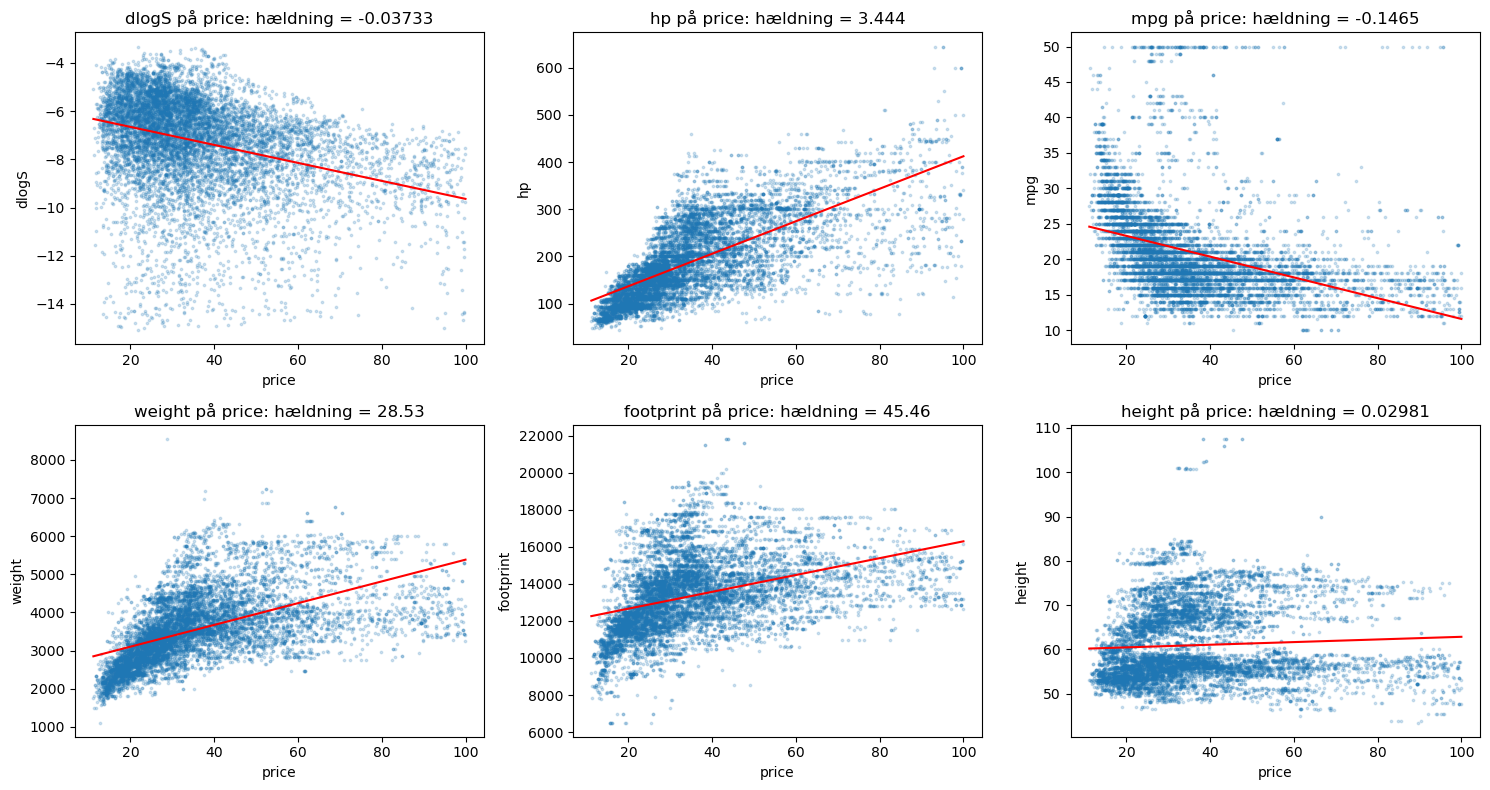

Korrelationer med pris og dlogS
              dlogS     price        hp       mpg    weight  footprint  \
dlogS      1.000000 -0.325879 -0.212328 -0.029636 -0.086062   0.054004   
price     -0.325879  1.000000  0.703196 -0.381227  0.544305   0.395439   
hp        -0.212328  0.703196  1.000000 -0.515324  0.727541   0.582349   
mpg       -0.029636 -0.381227 -0.515324  1.000000 -0.557579  -0.521406   
weight    -0.086062  0.544305  0.727541 -0.557579  1.000000   0.833413   
footprint  0.054004  0.395439  0.582349 -0.521406  0.833413   1.000000   
height     0.052683  0.060698  0.287080 -0.334672  0.712067   0.526091   

             height  
dlogS      0.052683  
price      0.060698  
hp         0.287080  
mpg       -0.334672  
weight     0.712067  
footprint  0.526091  
height     1.000000  


In [147]:
pairs = [('price', 'dlogS'), ('price','hp' ), ('price','mpg'), ('price','weight'),('price','footprint'),('price','height')]

fig, axes = plt.subplots(2,3,figsize=(15,8))
for ax, (xv,yv) in zip(axes.ravel(), pairs):
    ax.scatter(df[xv], df[yv], s=3, alpha=0.2)
    m = mlr.ols(y=df[yv],X=df[['const', xv]])
    grid = np.linspace(df[xv].min(),df[xv].max(),100)
    ax.plot(grid, m['beta_hat'][0,0] + m['beta_hat'][1,0]*grid, color='red')
    ax.set_xlabel(xv); ax.set_ylabel(yv)
    ax.set_title(f'{yv} på {xv}: hældning = {m['beta_hat'][1,0]:.4g}')
plt.tight_layout()
plt.show()

print('Korrelationer med pris og dlogS')
print(df[['dlogS','price','hp','mpg','weight','footprint','height']].corr())

### 1B
Fire OLS-specifikationer for $log(s_{jt}/s_{0t}) = dlogS$

In [148]:
y = df['dlogS']

#Variabellister
cont      = ['hp', 'mpg', 'height', 'footprint', 'weight', 'number_trims']
other     = ['releaseYear', 'yearsSinceDesign']
D_type    = ['sport', 'EV', 'truck', 'suv', 'van']
cont_log  = ['log_hp', 'log_mpg', 'log_height', 'log_footprint', 'log_weight', 'log_number_trims']

# Tidsdummies (1980 er referencekategori)
year_dummies = pd.get_dummies(df['year'], prefix='y', drop_first=True, dtype=int)
df = pd.concat([df, year_dummies], axis=1)
years = list(year_dummies.columns)

# Specifikation 1-4
m1 = mlr.ols(y=y, X=df[['const', 'price']])
m2 = mlr.ols(y=y, X=df[['const', 'price'] + cont + other + D_type])
m3 = mlr.ols(y=y, X=df[['const', 'price'] + cont + other + D_type + years])
m4 = mlr.ols(y=y, X=df[['const', 'price'] + cont_log + other + D_type + years])
models = [m1, m2, m3, m4]

# Fuld output (alle parametre og standardfejl, TSS/ESS/RSS og R2)
mlr.summary(models, column_titles=['Spec 1', 'Spec 2', 'Spec 3', 'Spec 4'])

                       Spec 1     Spec 2     Spec 3     Spec 4
Dependent variable    [dlogS]    [dlogS]    [dlogS]    [dlogS]
             const    -5.9072    -5.4138    -6.8066   -25.4344
                     (0.0439)   (0.2908)   (0.3177)   (1.6540)
             price    -0.0373    -0.0243    -0.0370    -0.0298
                     (0.0011)   (0.0016)   (0.0017)   (0.0014)
       releaseYear               -1.0643    -1.2272    -0.5031
                                (0.0614)   (0.0608)   (0.0542)
  yearsSinceDesign               -0.1269    -0.1278    -0.1077
                                (0.0059)   (0.0058)   (0.0050)
             sport               -0.6144    -0.6522    -0.5040
                                (0.0631)   (0.0618)   (0.0547)
                EV               -0.6321    -0.7759    -0.9254
                                (0.2060)   (0.2010)   (0.1688)
             truck               -0.1571    -0.3225    -0.6029
                                (0.0854)   (0.0835)   (

### 1C
Udfør test af $H_0 : \alpha = 0$, mod det tosidede alternativ $H_A : \alpha \neq 0$

In [ ]:
from scipy.stats import t as student_t

r1 = mlr.ols(y=y, X=df[['const', 'price']], robust=True)
r2 = mlr.ols(y=y, X=df[['const', 'price'] + cont + other + D_type], robust=True)
r3 = mlr.ols(y=y, X=df[['const', 'price'] + cont + other + D_type + years], robust=True)
r4 = mlr.ols(y=y, X=df[['const', 'price'] + cont_log + other + D_type + years], robust=True)
robust_models = [r1, r2, r3, r4]

def alpha_test(m):
    j = m['lbl_X'].index('price')
    return m['beta_hat'][j, 0], m['se'][j, 0], m['t_stats'][j, 0], m['p_values'][j, 0]
 
rows = []
for name, m, r in zip(['Spec 1', 'Spec 2', 'Spec 3', 'Spec 4'], models, robust_models):
    a, se, t, p = alpha_test(m)
    _, se_r, t_r, p_r = alpha_test(r)
    rows.append({'Spec': name, 'alpha_hat': a,
                 'SE': se, 't': t, 'p-værdi': p,
                 'Robust SE': se_r, 'Robust t': t_r, 'Robust p': p_r})
 
test_table = pd.DataFrame(rows).set_index('Spec')
print(test_table)

frihedsgrader = m4['n'] - m4['k']          # antal observationer minus antal parametre (inkl. konstant)
t_crit = student_t.ppf(0.975, frihedsgrader)
print(f"\nKritisk værdi (5%, tosidet), frihedsgrader = {frihedsgrader}: {t_crit:.3f}")

        alpha_hat        SE          t  p-værdi  Robust SE   Robust t  \
Spec                                                                    
Spec 1  -0.037326  0.001100 -33.934529      0.0   0.001044 -35.756000   
Spec 2  -0.024260  0.001611 -15.056687      0.0   0.001616 -15.013312   
Spec 3  -0.036958  0.001687 -21.903210      0.0   0.001694 -21.818086   
Spec 4  -0.029820  0.001422 -20.969296      0.0   0.001401 -21.281838   

        Robust p  
Spec              
Spec 1       0.0  
Spec 2       0.0  
Spec 3       0.0  
Spec 4       0.0  


AttributeError: 'numpy.float64' object has no attribute 'ppf'

### 2A

In [151]:
make_d = pd.get_dummies(df['make'], dtype=int).drop(columns='volvo')
df = df.drop(columns=[c for c in make_d.columns if c in df.columns])   # remove old copies
df = pd.concat([df, make_d], axis=1)
makes = list(make_d.columns)

def coef(m, name):
    j = m['lbl_X'].index(name)
    return m['beta_hat'][j, 0], m['se'][j, 0]

X_dum = ['const', 'price'] + x_vars + years + makes
m_dum = mlr.ols(y=y, X=df[X_dum])

vars_w = ['const', 'price'] + x_vars + years
df_w = df.copy()
for v in vars_w:
    df_w[v] = df[v] - df.groupby('make')[v].transform('mean')
    
X_w = ['price'] + x_vars + years
m_w = mlr.ols(y=df_w['dlogS'], X=df_w[X_w])

common = ['price'] + x_vars + years
diff = max(abs(coef(m_dum,v)[0]-coef(m_w,v)[0]) for v in common)
print(f"Maks. forskel i parameterestimater mellem de to modeller: {diff:.2e}")

cmp = pd.DataFrame({
    'alpha_hat': [coef(m_dum, 'price')[0], coef(m_w, 'price')[0]],
    'SE(alpha_hat)': [coef(m_dum, 'price')[1], coef(m_w, 'price')[1]],
    'TSS': [m_dum['TSS'], m_w['TSS']],
    'ESS': [m_dum['ESS'], m_w['ESS']],
    'RSS': [m_dum['RSS'], m_w['RSS']],
    'R2':  [m_dum['R_squared'], m_w['R_squared']],
    'k (parametre)': [m_dum['k'], m_w['k']],
}, index=['Make-dummies', 'Within'])
print(cmp)

 
# Standardfejl i within-modellen skal korrigeres for de G-1 absorberede mærke-effekter
G = df['make'].nunique()
corr = np.sqrt((m_w['n'] - m_w['k']) / (m_w['n'] - m_w['k'] - G))
print(f"\nWithin SE for alpha, df-korrigeret: {coef(m_w, 'price')[1] * corr:.6f}")
 
alpha_ols = coef(m_dum, 'price')[0]

Maks. forskel i parameterestimater mellem de to modeller: 1.20e-09
              alpha_hat  SE(alpha_hat)           TSS            ESS  \
Make-dummies  -0.033666       0.001737  37300.695201   21967.187278   
Within        -0.033666       0.010200  37300.695201 -494844.948703   

                        RSS         R2  k (parametre)  
Make-dummies   15333.507923   0.588922            114  
Within        532145.643904 -13.266373             52  

Within SE for alpha, df-korrigeret: 0.010233


### 2C

In [152]:
from scipy import stats

def first_stage_F(endog, X1, Ze):
    """First stage: regress endog on [X1, Ze]. F-test of H0: Ze coefficients = 0."""
    m_ur = mlr.ols(y=endog, X=pd.concat([X1, Ze], axis=1))
    m_r  = mlr.ols(y=endog, X=X1)
    rss_ur = float(np.sum(m_ur['u_hat']**2))
    rss_r  = float(np.sum(m_r['u_hat']**2))
    q, n, k = Ze.shape[1], len(endog), X1.shape[1] + Ze.shape[1]
    F = ((rss_r - rss_ur) / q) / (rss_ur / (n - k))
    return m_ur, F, n - k            # model, F-statistic, residual df

X1_cols = ['const'] + x_vars + years + makes

fs, F_rxr, dof = first_stage_F(df['price'], df[X1_cols], df[['RXR']])
g1, g1_se = coef(fs, 'RXR')
t = g1 / g1_se
p = 2 * (1 - stats.t.cdf(abs(t), dof))
print(f"First stage: gamma1 = {g1:.4f}, se = {g1_se:.4f}, t = {t:.2f}, p = {p:.4f}, F = {F_rxr:.1f}")
 
m_iv_rxr = mlr.tsls(y=y, X1=df[X1_cols], X2=df[['price']], Ze=df[['RXR']])
a_iv, a_iv_se = coef(m_iv_rxr, 'price')
print(f"OLS (make-dummies): alpha = {alpha_ols:.4f}")
print(f"2SLS (RXR):         alpha = {a_iv:.4f}  (se = {a_iv_se:.4f})")
 
alpha_iv = a_iv

First stage: gamma1 = 4.1465, se = 0.5157, t = 8.04, p = 0.0000, F = 64.6


OLS (make-dummies): alpha = -0.0337
2SLS (RXR):         alpha = -0.1694  (se = 0.0272)


### 3A

In [153]:
gh = ['gh_log_height', 'gh_log_footprint', 'gh_log_hp', 'gh_log_mpg', 'gh_log_weight']
 
m_gh     = mlr.tsls(y=y, X1=df[X1_cols], X2=df[['price']], Ze=df[gh])
m_gh_rxr = mlr.tsls(y=y, X1=df[X1_cols], X2=df[['price']], Ze=df[gh + ['RXR']])
 
# First-stage F-test for de ekskluderede instrumenter
F_gh     = first_stage_F(df['price'], df[X1_cols], df[gh])[1]
F_gh_rxr = first_stage_F(df['price'], df[X1_cols], df[gh + ['RXR']])[1]
 
rows = []
for name, m, n_iv, F in [('RXR', m_iv_rxr, 1, F_rxr), ('GH', m_gh, len(gh), F_gh),
                         ('GH + RXR', m_gh_rxr, len(gh) + 1, F_gh_rxr)]:
    a, se = coef(m, 'price')
    dof = n_iv - 1                                  # #instrumenter - #endogene variable
    J, pJ = (m['J_stat'], m['pval_Jstat']) if dof > 0 else (np.nan, np.nan)
    rows.append({'Instrumenter': name, 'alpha_hat': a, 'SE': se,
                 'First-stage F': F, 'Sargan J': J, 'df': dof, 'p-værdi (J)': pJ})
tab_3A = pd.DataFrame(rows).set_index('Instrumenter')
print(f"OLS (make-dummies): alpha = {alpha_ols:.4f}")
print(tab_3A)

OLS (make-dummies): alpha = -0.0337
              alpha_hat        SE  First-stage F   Sargan J  df   p-værdi (J)
Instrumenter                                                                 
RXR           -0.169394  0.027150      64.637040        NaN   0           NaN
GH            -0.018954  0.004108     420.710821  30.913450   4  3.188401e-06
GH + RXR      -0.025042  0.004004     371.092431  80.280045   5  7.771561e-16


### 3B

alpha_OLS = -0.0337,  alpha_IV = -0.1694
Andel med mc <= 0: OLS 0.443,  IV 0.000
Andel med |elasticitet| < 1: OLS 0.443,  IV 0.000
                 mean        std        min        10%        50%        90%  \
OLS mc       6.302114  17.143271 -18.686447 -11.079508   2.087541  29.971433   
    elast   -1.212193   0.576811  -3.365303  -2.008336  -1.070259  -0.627323   
    markup   0.999042   0.424653   0.297150   0.497925   0.934354   1.594074   
IV  mc      30.135872  17.129868   5.215940  12.742510  25.907497  53.775804   
    elast   -6.099203   2.902250 -16.932669 -10.105032  -5.385053  -3.156406   
    markup   0.198556   0.084398   0.059057   0.098961   0.185699   0.316816   

                  max  
OLS mc      70.275425  
    elast   -0.373594  
    markup   2.676699  
IV  mc      94.081449  
    elast   -1.879757  
    markup   0.531984  


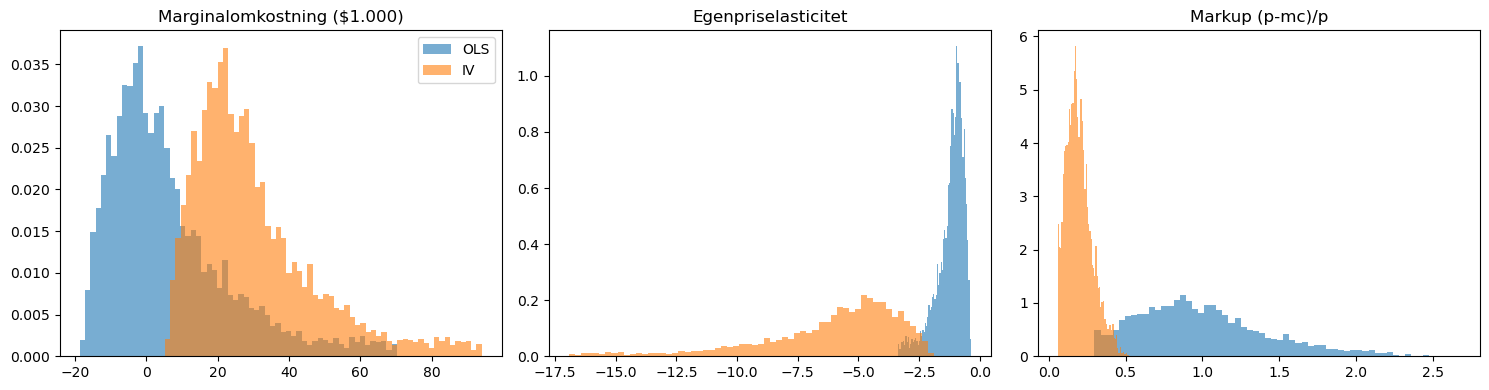

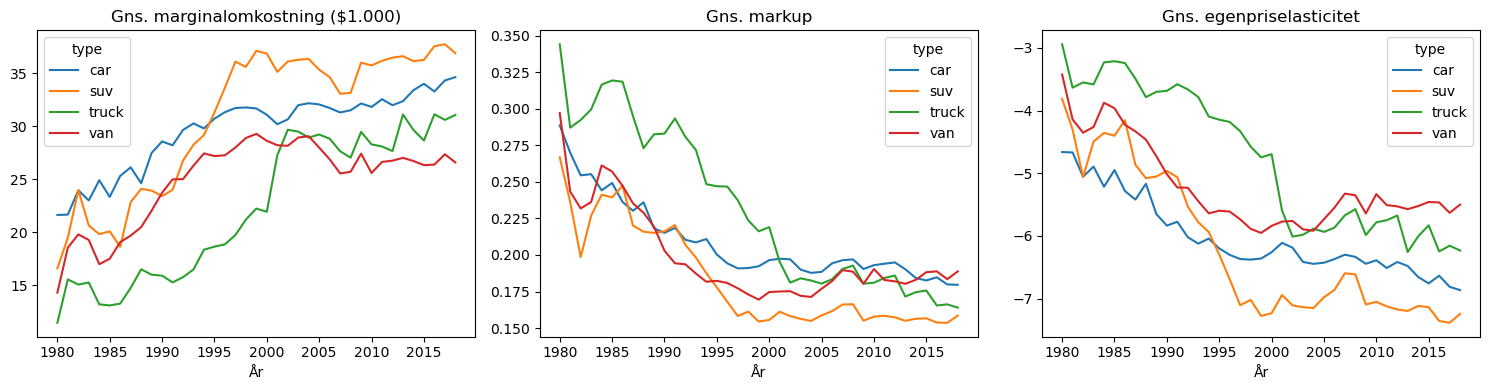

In [154]:
def structural(alpha, d):
    out = pd.DataFrame(index=d.index)
    out['mc']     = d['price'] - 1 / (-alpha * (1 - d['market_share']))
    out['elast']  = alpha * d['price'] * (1 - d['market_share'])
    out['markup'] = (d['price'] - out['mc']) / d['price']
    return out
 
ols_res = structural(alpha_ols, df)
iv_res  = structural(alpha_iv,  df)
 
print(f"alpha_OLS = {alpha_ols:.4f},  alpha_IV = {alpha_iv:.4f}")
print(f"Andel med mc <= 0: OLS {np.mean(ols_res['mc'] <= 0):.3f},  IV {np.mean(iv_res['mc'] <= 0):.3f}")
print(f"Andel med |elasticitet| < 1: OLS {np.mean(ols_res['elast'].abs() < 1):.3f},  "
      f"IV {np.mean(iv_res['elast'].abs() < 1):.3f}")
 
summ = pd.concat({'OLS': ols_res.describe(percentiles=[.1, .5, .9]).T,
                  'IV':  iv_res.describe(percentiles=[.1, .5, .9]).T})
print(summ[['mean', 'std', 'min', '10%', '50%', '90%', 'max']])
 
# Fordelinger: OLS vs IV
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (v, lab) in zip(axes, [('mc', 'Marginalomkostning ($1.000)'),
                               ('elast', 'Egenpriselasticitet'),
                               ('markup', 'Markup (p-mc)/p')]):
    ax.hist(ols_res[v], bins=60, alpha=0.6, density=True, label='OLS')
    ax.hist(iv_res[v],  bins=60, alpha=0.6, density=True, label='IV')
    ax.set_title(lab)
axes[0].legend()
plt.tight_layout()
plt.show()

# Udvikling over tid pr. biltype (IV)
d = df[['year', 'type']].join(iv_res)
types = ['car', 'suv', 'truck', 'van']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (v, lab) in zip(axes, [('mc', 'Gns. marginalomkostning ($1.000)'),
                               ('markup', 'Gns. markup'),
                               ('elast', 'Gns. egenpriselasticitet')]):
    d.groupby(['year', 'type'])[v].mean().unstack()[types].plot(ax=ax)
    ax.set_title(lab); ax.set_xlabel('År')
plt.tight_layout()
plt.show()
 

### 3C

Observationer med mc <= 0 udelades: 0
                  gamma_hat        SE
const             -6.052680  0.255340
log_hp             0.466264  0.013603
log_mpg            0.111537  0.015672
log_height        -0.776484  0.038159
log_footprint     -0.136787  0.034227
log_weight         1.361861  0.029090
log_number_trims  -0.030632  0.002593
releaseYear       -0.012594  0.007521
yearsSinceDesign  -0.001050  0.000716
sport              0.156260  0.007829
EV                 0.352478  0.025093
truck             -0.147870  0.010166
suv                0.012791  0.008080
van               -0.003481  0.011578
RXR                0.176486  0.013235
R2 = 0.8793, n = 9694
1981    0.162
1982    0.239
1983    0.254
1984    0.225
1985    0.212
1986    0.243
1987    0.268
1988    0.241
1989    0.249
1990    0.223
1991    0.200
1992    0.201
1993    0.191
1994    0.185
1995    0.194
1996    0.187
1997    0.176
1998    0.178
1999    0.171
2000    0.140
2001    0.111
2002    0.099
2003    0.073
2004    0.

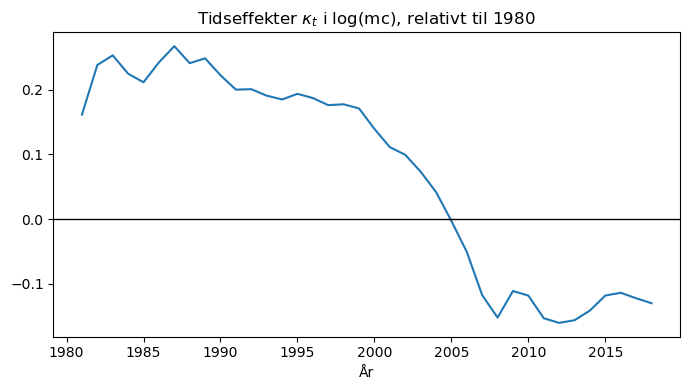

In [155]:
pos = iv_res['mc'] > 0
print(f"Observationer med mc <= 0 udelades: {(~pos).sum()}")
dd = df[pos].copy()
dd['log_mc'] = np.log(iv_res.loc[pos, 'mc'])
 
X_mc = ['const'] + x_vars + ['RXR'] + years + makes
m_mc = mlr.ols(y=dd['log_mc'], X=dd[X_mc])
 
shown = ['const'] + x_vars + ['RXR']
print(pd.DataFrame({'gamma_hat': [coef(m_mc, v)[0] for v in shown],
                    'SE': [coef(m_mc, v)[1] for v in shown]}, index=shown))
print(f"R2 = {m_mc['R_squared']:.4f}, n = {m_mc['n']}")
 
# Tidseffekter (kappa_t) relativt til 1980
kappa = pd.Series({y_: coef(m_mc, y_)[0] for y_ in years})
kappa.index = [int(i[2:]) for i in kappa.index]
print(kappa.round(3).to_string())
 
plt.figure(figsize=(7, 4))
kappa.plot()
plt.axhline(0, color='black', lw=1)
plt.title(r'Tidseffekter $\kappa_t$ i log(mc), relativt til 1980')
plt.xlabel('År')
plt.tight_layout()
plt.show()

### 4C


In [156]:
np.random.seed(2308)


In [157]:
def simulate_eq(n, beta0, beta1, gamma0, gamma1, gamma2):
    z = np.random.normal(0,1,n)
    xi = np.random.normal(0,1,n)
    nu = np.random.normal(0,1,n)
    
    diff = beta1 - gamma1
    eta0 = (gamma0 - beta0) / diff
    eta1 = gamma2 / diff
    u = (nu - xi) / diff
    
    p = eta0 + eta1 * z + u # Den reducerede ligning for prisen
    y = beta0 + beta1 * p + xi # efterspørgselslignigen
    return pd.DataFrame({'y': y, 'const': 1.0, 'p': p, 'z': z, 'xi': xi, 'nu':nu})

In [158]:
def simulate(n, r, **parametre):
    b_ols = np.empty(r)
    b_iv = np.empty(r)
    for s in range(r):
        df = simulate_eq(n, **parametre)
        b_ols[s] = mlr.ols(y=df['y'], X=df[['const', 'p']])['beta_hat'][1,0]
        b_iv[s] = mlr.tsls(y=df['y'], X1=df[['const']], X2=df[['p']],Ze=df[['z']])['beta_hat'][1,0]
    
    return b_ols, b_iv

Definere de forskellige scenearier og relevante variable til simulationen

In [159]:
n, r = 500, 500

baseline = dict(beta0 = 0.5, beta1 =-0.1, gamma0 = 0.25, gamma1=1.0, gamma2 = 1.0)

scenarier = {
    'Scenarie 1' : dict(baseline),
    'Scenarie 2' : dict(baseline, gamma2=0.25),
    'Scenarie 3' : dict(baseline, gamma1=0.25),
}

Her under kører jeg de tre scenarier, og printer bias og barians for både IV og OLS

In [160]:
rows = []
for name, parametre in scenarier.items():
    b_ols, b_iv = simulate(n,r,**parametre)
    b1 = parametre['beta1']
    rows.append({
        'Scenarie': name,
        'OLS bias': b_ols.mean() - b1,
        'OLS varians': b_ols.var(ddof=1),
        'IV bias': b_iv.mean() - b1,
        'IV varians': b_iv.var(ddof=1),
    })
    
summary = pd.DataFrame(rows).set_index('Scenarie')
print(summary)

            OLS bias  OLS varians   IV bias  IV varians
Scenarie                                               
Scenarie 1  0.367467     0.000528 -0.002642    0.002362
Scenarie 2  0.532551     0.000564 -0.024437    0.074585
Scenarie 3  0.116338     0.000049  0.000080    0.000251


Regne styrken af vores instrument ud:
$\eta_1 = \frac{\gamma_2}{\beta_1 - \gamma_1}$

In [161]:
rows = []
for name, parametre in scenarier.items():
    rows.append({
        'Scenarie': name,
        'eta1': parametre['gamma2']/(parametre['beta1']-parametre['gamma1'])
    })
summary = pd.DataFrame(rows).set_index('Scenarie')
print(summary)

                eta1
Scenarie            
Scenarie 1 -0.909091
Scenarie 2 -0.227273
Scenarie 3 -2.857143
